In [ ]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from collections import defaultdict

from scipy.sparse import csr_matrix, diags, eye
from scipy.sparse.linalg import eigsh, lobpcg
import networkx as nx

from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

import tqdm
from scipy.sparse.linalg import norm

from utils import *

In [16]:

k_nn = 3
n_clusters = 10
random_state = 81


In [17]:
import keras.datasets.mnist
print("Loading MNIST subset...")
(X, y), (test_x, _) = keras.datasets.mnist.load_data()


Loading MNIST subset...


In [18]:

print("Building graphs...")
W_G = build_knn_graph(np.reshape(X, (len(X), -1)), k=3, use_gaussian=False, sigma=2)
G = nx.from_scipy_sparse_matrix(W_G)

Building graphs...


C:\Users\songs\AppData\Local\Temp\ipykernel_18400\345025078.py:3: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  G = nx.from_scipy_sparse_matrix(W_G)


# Spectral Clustering

In [19]:

deg_g = np.array(W_G.sum(axis=1)).ravel()
normalized_Lap_G = normalized_laplacian_from_D_sp(W_G, (deg_g))
sc_labels, _, _ = spectral_clustering(
    normalized_Lap_G, 
    n_clusters=n_clusters,
    random_state=random_state
)
sc_ari = adjusted_rand_score(y, sc_labels)
sc_nmi = normalized_mutual_info_score(y, sc_labels)
sc_cut = max(conductance_all_clusters(G, sc_labels).values())
print("SC ARI between clustering and true labels:", sc_ari)
print("SC NMI between clustering and true labels:", sc_nmi)
print("Spectral clustering cut: ", sc_cut)

SC ARI between clustering and true labels: 0.6020850611575523
SC NMI between clustering and true labels: 0.7684691686682337
Spectral clustering cut:  0.10006303183107469


# ICSC

In [20]:
aris = []
nmis = []
aris.append(sc_ari)
nmis.append(sc_nmi)
cut_gh = []
cut_g = []
cut_g.append(sc_cut)
cut_gh.append(None)
pred_labels = sc_labels
n_neighbors = 5
for i in range(10):
    W_H = build_cannot_link_graph(pred_labels, n_cl=n_neighbors + i, random_state=random_state)
    H = nx.from_scipy_sparse_matrix(W_H)
    pred_labels, vals, vecs = iterative_clustering(W_G, W_H, k = n_clusters, exact=False, eps = 0.95, random_seed=random_state)
    generalized_spectral_clustering_ari = adjusted_rand_score(y, pred_labels)
    generalized_spectral_clustering_nmi = normalized_mutual_info_score(y, pred_labels)
    print(f"{i+1}th iteration: Constrained Spectral Clustering ARI: {generalized_spectral_clustering_ari:.4f}")
    print(f"{i+1}th iteration: Constrained Spectral Clustering NMI: {generalized_spectral_clustering_nmi:.4f}")
    generalized_cutratio = max(ratiocut_all_clusters(G, H, pred_labels).values())
    print("cutratio ", generalized_cutratio)
    generalized_spectral_clustering_cut = max(conductance_all_clusters(G, pred_labels).values())
    print("Conductance ", generalized_spectral_clustering_cut)
    aris.append(generalized_spectral_clustering_ari)
    nmis.append(generalized_spectral_clustering_nmi)
    cut_g.append(generalized_spectral_clustering_cut)
    cut_gh.append(generalized_cutratio)

C:\Users\songs\AppData\Local\Temp\ipykernel_18400\800267128.py:13: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


1th iteration: Constrained Spectral Clustering ARI: 0.6804
1th iteration: Constrained Spectral Clustering NMI: 0.8079
cutratio  0.022889556222889556
Conductance  0.047619047619047616


C:\Users\songs\AppData\Local\Temp\ipykernel_18400\800267128.py:13: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


2th iteration: Constrained Spectral Clustering ARI: 0.7011
2th iteration: Constrained Spectral Clustering NMI: 0.8095
cutratio  0.037562604340567615
Conductance  0.08913832948167712


C:\Users\songs\AppData\Local\Temp\ipykernel_18400\800267128.py:13: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)
C:\Users\songs\AppData\Local\Temp\ipykernel_18400\1570376531.py:186: UserWarning: Exited at iteration 200 with accuracies 
[2.26481623e-07 6.04294493e-07 4.60013019e-07 5.32113943e-07
 6.05800203e-07 6.92013582e-07 7.56371635e-07 6.25575843e-07
 5.50338817e-07 8.48429925e-06]
not reaching the requested tolerance 1e-06.
Use iteration 201 instead with accuracy 
1.3537302407234308e-06.

  vals, vecs = lobpcg(L_G_sym, X0, B=L_H_sym_reg, largest=False, tol=1e-6, maxiter=200)
C:\Users\songs\AppData\Local\Temp\ipykernel_18400\1570376531.py:186: UserWarning: Exited postprocessing with accuracies 
[2.26481623e-07 6.04294493e-07 4.60013019e-07 5.32113943e-07
 6.05800203e-07 6.92013582e-07 7.56371635e-07 6.25575843e-07
 5.50338817e-07 8.48429925e-06]

...

8th iteration: Constrained Spectral Clustering ARI: 0.8186
8th iteration: Constrained Spectral Clustering NMI: 0.8637
cutratio  0.026278964969285865
Conductance  0.12019960945975265


C:\Users\songs\AppData\Local\Temp\ipykernel_18400\800267128.py:13: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)
C:\Users\songs\AppData\Local\Temp\ipykernel_18400\1570376531.py:186: UserWarning: Exited at iteration 200 with accuracies 
[4.43622745e-07 3.32071703e-07 5.54007034e-07 4.32946814e-07
 6.98427297e-07 6.53749436e-07 5.35655777e-07 6.93325904e-07
 5.64019954e-07 9.17442103e-05]
not reaching the requested tolerance 1e-06.
Use iteration 201 instead with accuracy 
9.665203699905057e-06.

  vals, vecs = lobpcg(L_G_sym, X0, B=L_H_sym_reg, largest=False, tol=1e-6, maxiter=200)
C:\Users\songs\AppData\Local\Temp\ipykernel_18400\1570376531.py:186: UserWarning: Exited postprocessing with accuracies 
[4.43622745e-07 3.32071703e-07 5.54007035e-07 4.32946814e-07
 6.98427297e-07 6.53749436e-07 5.35655777e-07 6.93325904e-07
 5.64019954e-07 9.17442103e-05]


9th iteration: Constrained Spectral Clustering ARI: 0.7642
9th iteration: Constrained Spectral Clustering NMI: 0.8497
cutratio  0.007629308243552869
Conductance  0.04275372216910258


C:\Users\songs\AppData\Local\Temp\ipykernel_18400\800267128.py:13: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


10th iteration: Constrained Spectral Clustering ARI: 0.7686
10th iteration: Constrained Spectral Clustering NMI: 0.8520
cutratio  0.006934322936520394
Conductance  0.042162309553836194


# Plot Results

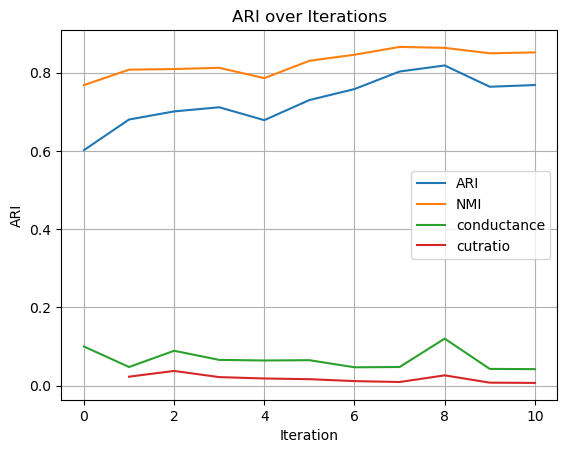

In [21]:
import matplotlib.pyplot as plt

plt.plot(aris, label = "ARI")
plt.plot(nmis, label = "NMI")
plt.plot(cut_g, label = "conductance")
plt.plot(cut_gh, label = "cutratio")
plt.xlabel('Iteration')
plt.ylabel('ARI')
plt.title('ARI over Iterations')
plt.legend()
plt.grid()
plt.show()